# Stage 2: AI-enhanced joint BiGRU (intent + slots), MASSIVE 1.0 en-US

This notebook trains and evaluates the **Stage-2** system. The model code is in `joint_bigru_stage2.py`.
It reuses the Stage-1 module (`joint_bigru_attention_crf.py`) for dataset loading, BIO conversion and
span decoding, so both stages are scored by identical rules.

**Constraints followed:**
- Official splits only (asserted below); the only model input is `utt`.
- No pretrained models. The only pretrained resource is **GloVe 6B word vectors**, which the
  assignment explicitly allows ("No pretrained models are allowed (except word vectors)").
  They are frozen and counted in the parameter total.
- Vocabulary comes from the training split, extended with the most frequent GloVe words. The
  validation and test splits are never used to choose words.
- Each member is one joint model for both tasks, and the ensemble outputs one intent and one slot set
  per utterance. Total parameters, including word vectors, are ≤ 20M (asserted below).

### Weaknesses found in the Stage-1 baseline and what we changed
| # | Stage-1 weakness (diagnosis) | Stage-2 change |
|---|---|---|
| 1 | ~17% of dev/test utterances contain a word not in the training vocab, and the `<unk>` embedding is never trained (every training word is in the vocab) | **Frozen GloVe vectors** over the training vocab + 20,000 frequent GloVe words; **character CNN**; **frequency-based word dropout** on the trainable embedding (p = 0.25/(0.25+count)) |
| 2 | The CRF can output invalid BIO sequences (e.g. `O → I-time`), which produce broken spans | **CRF with hard BIO constraints** |
| 3 | Slot tagging can't see the intent | **Intent-conditioned slot emissions** (sentence vector fed to every token's slot head) |
| 4 | Single attention pooling; small encoder (128/dir) | **Attention + max pooling**, wider BiGRU |
| 5 | Fixed LR; 70 s/epoch on MPS; one model's variance | **AdamW + warm-up + cosine decay**, intent label smoothing; CPU training (deterministic, faster); **ensemble of 4 seeds**, averaging intent probabilities and CRF scores |

### Development history (all selection on **validation**)
Single models, 40 epochs, seed 42, 4 CPU threads (exploration runs, outside this notebook):

| Run | Configuration | Val intent (%) | Val slot F1 (%) | Val combined |
|---|---|---|---|---|
| Stage-1 | baseline (random init, BiGRU 128, CRF) | 84.01 | 78.98 | 81.50 |
| A | changes 1-5 without GloVe, + residual self-attention, dropout 0.4 | 82.05 | 76.22 | 79.13 |
| B | A without self-attention | 85.83 | 79.45 | 82.64 |
| C | B with dropout 0.3 / emb-dropout 0.15 (executed in `model_stage2_noglove.ipynb`) | 85.69 | 80.33 | 83.01 |
| D | B with dropout 0.5 / emb-dropout 0.3 | 83.92 | 78.65 | 81.29 |
| X | C + frozen GloVe 100-d (+50k words), BiGRU 224, trainable emb 150 | 86.97 | 81.70 | 84.33 |
| **Y** | **C + frozen GloVe 300-d (+20k words), BiGRU 192, trainable emb 150 (selected)** | **87.06** | **81.75** | **84.41** |

- **Rejected:** self-attention lowered combined validation by ~3.5 points. Dropout 0.5 under-fit.
- **Sizing:** GloVe settings X and Y were sized so that 4 members plus the shared GloVe table stay under 20M.
- **Final system:** Y was selected (higher validation score) and is trained below with 4 seeds, then ensembled.

In [1]:
import json, time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from torch.utils.data import DataLoader

import joint_bigru_attention_crf as stage1
import joint_bigru_stage2 as s2

DATA_PATH = Path("1.0/data/en-US.jsonl")
GLOVE_PATH = Path('glove/glove.6B.300d.txt')   # GloVe 6B, https://nlp.stanford.edu/projects/glove/
GLOVE_EXTRA_WORDS = 20000
N_MEMBERS = 4
OUTPUT_DIR = Path("stage2_final_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
print("torch", torch.__version__)

torch 2.9.0


## 1. Load and verify the dataset (official partitions)

In [2]:
data = s2.prepare(DATA_PATH, GLOVE_PATH, GLOVE_EXTRA_WORDS)   # read_data asserts the split sizes
splits = data["splits"]
print({k: len(v) for k, v in splits.items()})
assert len(splits["train"]) == 11514
assert len(splits["dev"]) == 2033
assert len(splits["test"]) == 2974

Dataset split sizes: {'train': 11514, 'dev': 2033, 'test': 2974}
Vocabulary size: 5146
Number of intents: 60
Number of BIO tags: 111


GloVe: {"glove_file": "glove.6B.300d.txt", "dimension": 300, "train_vocab_words_with_vector": 4963, "train_vocab_size_excluding_special": 5144, "train_vocab_coverage_percent": 96.48, "extra_glove_words_added": 20000, "extended_vocab_size": 25146}


Character vocabulary size: 34
{'train': 11514, 'dev': 2033, 'test': 2974}


## 2. Preprocessing: tokens, characters, BIO tags

In [3]:
record = splits["train"][0]
words, tags = stage1.record_to_tokens_tags(record)
print("utt      :", record["utt"])
print("annot_utt:", record["annot_utt"])
print("intent   :", record["intent"])
for w, t in zip(words, tags):
    print(f"  {w:10s} {t}")
print("gold slots:", data["datasets"]["train"][0]["gold_slots"])
print("training vocab:", data["train_vocab_size"], "| extended vocab (with GloVe words):", len(data["vocab"]),
      "| chars:", len(data["char_to_id"]), "| intents:", len(data["intent_to_id"]), "| BIO tags:", len(data["tag_to_id"]))
print(json.dumps(data["glove_info"], indent=2))

utt      : wake me up at nine am on friday
annot_utt: wake me up at [time : nine am] on [date : friday]
intent   : alarm_set
  wake       O
  me         O
  up         O
  at         O
  nine       B-time
  am         I-time
  on         O
  friday     B-date
gold slots: {('date', 'friday'), ('time', 'nine am')}
training vocab: 5146 | extended vocab (with GloVe words): 25146 | chars: 34 | intents: 60 | BIO tags: 111
{
  "glove_file": "glove.6B.300d.txt",
  "dimension": 300,
  "train_vocab_words_with_vector": 4963,
  "train_vocab_size_excluding_special": 5144,
  "train_vocab_coverage_percent": 96.48,
  "extra_glove_words_added": 20000,
  "extended_vocab_size": 25146
}


### Diagnosis: out-of-vocabulary words, and how much GloVe recovers

In [4]:
train_counts = Counter(w.lower() for r in splits["train"] for w in stage1.record_to_tokens_tags(r)[0])
glove_rows = data["glove_vectors"].abs().sum(1) > 0
print("training word types:", len(train_counts), "| seen once:", sum(c == 1 for c in train_counts.values()))
for split in ["dev", "test"]:
    toks = [[w.lower() for w in stage1.record_to_tokens_tags(r)[0]] for r in splits[split]]
    oov = [w for t in toks for w in t if w not in train_counts]
    n_tok = sum(map(len, toks))
    with_vec = sum(1 for w in oov if w in data["vocab"] and glove_rows[data["vocab"][w]])
    print(f"{split}: {100*len(oov)/n_tok:.2f}% of tokens unseen in training; "
          f"{100*sum(any(w not in train_counts for w in t) for t in toks)/len(toks):.2f}% of utterances contain one; "
          f"{100*with_vec/len(oov):.2f}% of those unseen tokens get a GloVe vector")

training word types: 5144 | seen once: 2420
dev: 3.08% of tokens unseen in training; 17.27% of utterances contain one; 70.09% of those unseen tokens get a GloVe vector
test: 3.23% of tokens unseen in training; 18.19% of utterances contain one; 68.28% of those unseen tokens get a GloVe vector


## 3. Shared evaluation functions
`s2.compute_metrics` computes **intent accuracy** = 100 × correct / N and **slot micro-F1** = 100 × 2TP / (2TP + FP + FN)
over exact `(slot type, span text)` pairs pooled across all utterances. Spans come from Stage-1's `decode_slots`.
To check the scorer, we reload the **Stage-1 checkpoint** and confirm this function gives exactly the same
numbers as Stage-1's own `evaluate`.

In [5]:
def evaluate_stage1_checkpoint(path, split):
    ck = torch.load(path, map_location="cpu", weights_only=False)
    m = stage1.JointBiGRUAttentionCRF(len(ck["vocab"]), len(ck["intent_to_id"]), len(ck["tag_to_id"]))
    m.load_state_dict(ck["model"]); m.eval()
    id_to_tag = {i: t for t, i in ck["tag_to_id"].items()}
    loader = DataLoader(stage1.MassiveDataset(splits[split], ck["vocab"], ck["intent_to_id"], ck["tag_to_id"]),
                        batch_size=64, collate_fn=stage1.collate)
    pi, gi, ps, gs = [], [], [], []
    with torch.no_grad():
        for b in loader:
            out = m(b["tokens"], b["mask"])
            pi += out["intent_logits"].argmax(1).tolist(); gi += b["intents"].tolist()
            for utt, path_, gold in zip(b["utts"], m.crf.decode(out["emissions"], mask=b["mask"]), b["gold_slots"]):
                ps.append(stage1.decode_slots(utt, path_, id_to_tag)); gs.append(gold)
    shared = s2.compute_metrics(pi, gi, ps, gs)
    own = stage1.evaluate(m, loader, "cpu", id_to_tag)
    assert abs(shared["intent_accuracy"] - own["intent_accuracy"]) < 1e-9
    assert abs(shared["slot_micro_f1"] - own["slot_micro_f1"]) < 1e-9
    n_params = sum(p.numel() for p in m.parameters())
    return shared, n_params, ck["epoch"]

stage1_results = {}
for split in ["dev", "test"]:
    res, stage1_params, stage1_epoch = evaluate_stage1_checkpoint("stage2_outputs/best_bigru_attention_crf.pt", split)
    stage1_results[split] = res
    print(f"Stage-1 {split:4s}: intent {res['intent_accuracy']:.2f}% | slot micro-F1 {res['slot_micro_f1']:.2f}%")
print("Shared scorer matches Stage-1's evaluate() exactly.")

Stage-1 dev : intent 84.01% | slot micro-F1 78.98%


Stage-1 test: intent 82.82% | slot micro-F1 75.63%
Shared scorer matches Stage-1's evaluate() exactly.


## 4. Stage-2 model and parameter budget
**Member inputs:** [frozen GloVe 300-d ‖ trainable training-vocab embedding ‖ char-CNN (kernels 2/3/4)] from `utt` only.
**Encoder:** 2-layer BiGRU. **Intent head:** [attention pooling ‖ max pooling] → MLP → 60 intents.
**Slot head:** [token state ‖ tanh(W·sentence vector)] → MLP → BIO emissions → BIO-constrained CRF.
**Loss:** label-smoothed intent cross-entropy + CRF negative log-likelihood. **Optimizer:** AdamW, warm-up + cosine decay.
**Ensemble:** each member is trained independently with a different seed and its best-validation checkpoint is kept.
The system averages member intent probabilities, and averages emission and transition scores before one Viterbi decode.
The frozen GloVe table is shared, so it is counted once.
**Selection criterion:** validation combined score = (intent accuracy + slot micro-F1) / 2, the same as Stage 1.

In [6]:
MEMBER_CONFIG = {**s2.DEFAULT_CONFIG, **{"hidden_size": 192, "embed_dim": 150, "threads": 8}}
SEEDS = [MEMBER_CONFIG["seed"] + i for i in range(N_MEMBERS)]
print(json.dumps(MEMBER_CONFIG, indent=2), "\nseeds:", SEEDS)

member = s2.build_model(data, MEMBER_CONFIG)
print(member)
m_total, m_trainable = s2.count_parameters(member)
ensemble_skeleton = s2.JointEnsemble([s2.build_model(data, MEMBER_CONFIG) for _ in SEEDS])
total_params, trainable_params = s2.count_parameters(ensemble_skeleton)
print(f"One member  : total {m_total:,} | trainable {m_trainable:,} | frozen GloVe {data['glove_vectors'].numel():,}")
print(f"Full system : total {total_params:,} | trainable {trainable_params:,}  ({N_MEMBERS} members, shared GloVe)")
assert total_params <= 20_000_000
print("Within the 20M parameter budget (word vectors included).")
del member, ensemble_skeleton

{
  "seed": 42,
  "epochs": 40,
  "batch_size": 32,
  "lr": 0.002,
  "weight_decay": 0.01,
  "warmup_epochs": 1,
  "clip": 5.0,
  "unk_z": 0.25,
  "embed_dim": 150,
  "char_dim": 48,
  "char_filters": 64,
  "char_kernels": [
    2,
    3,
    4
  ],
  "hidden_size": 192,
  "layers": 2,
  "heads": 8,
  "use_self_attention": false,
  "intent_context_dim": 128,
  "dropout": 0.3,
  "emb_dropout": 0.15,
  "label_smoothing": 0.1,
  "threads": 8
} 
seeds: [42, 43, 44, 45]
JointBiGRUStage2(
  (embedding): Embedding(5146, 150, padding_idx=0)
  (glove): Embedding(25146, 300, padding_idx=0)
  (char_cnn): CharCNN(
    (embedding): Embedding(34, 48, padding_idx=0)
    (convs): ModuleList(
      (0): Linear(in_features=96, out_features=64, bias=True)
      (1): Linear(in_features=144, out_features=64, bias=True)
      (2): Linear(in_features=192, out_features=64, bias=True)
    )
  )
  (emb_dropout): Dropout(p=0.15, inplace=False)
  (encoder): GRU(642, 192, num_layers=2, batch_first=True, dropout=0.

## 5. Train and select each member (train split only; best validation epoch kept)

In [7]:
runs = []
for i, seed in enumerate(SEEDS, 1):
    print(f"\n{'=' * 30} Member {i}/{N_MEMBERS} (seed {seed}) {'=' * 30}")
    runs.append(s2.train_model(data, {**MEMBER_CONFIG, "seed": seed}, OUTPUT_DIR,
                               checkpoint_name=f"member{i}_seed{seed}.pt"))


============================== Member 1/4 (seed 42) ==============================
Total parameters:     10,597,503
Trainable parameters: 3,053,703


Epoch  1/40 | train loss 9.9460 | val loss 3.9865 | val intent 67.73% | val slot F1 59.70% | combined 63.72 | 27.3s  <- best, saved


Epoch  2/40 | train loss 3.8729 | val loss 3.0237 | val intent 80.67% | val slot F1 73.04% | combined 76.85 | 27.8s  <- best, saved


Epoch  3/40 | train loss 3.0794 | val loss 2.7331 | val intent 81.36% | val slot F1 76.15% | combined 78.75 | 25.0s  <- best, saved


Epoch  4/40 | train loss 2.6914 | val loss 2.8002 | val intent 82.88% | val slot F1 76.73% | combined 79.80 | 26.7s  <- best, saved


Epoch  5/40 | train loss 2.4751 | val loss 2.7618 | val intent 84.11% | val slot F1 77.74% | combined 80.93 | 26.8s  <- best, saved


... (155 outputs left out)

Epoch 38/40 | train loss 1.0066 | val loss 3.5158 | val intent 87.06% | val slot F1 81.83% | combined 84.45 | 33.4s


Epoch 39/40 | train loss 1.0097 | val loss 3.5178 | val intent 87.06% | val slot F1 81.83% | combined 84.45 | 35.5s


Epoch 40/40 | train loss 1.0037 | val loss 3.5182 | val intent 87.06% | val slot F1 81.83% | combined 84.45 | 34.2s



Total training time: 21.2 min
Best epoch: 31
Best validation score (combined): 84.62 (intent 87.11%, slot F1 82.13%)
Checkpoint: stage2_final_outputs/member4_seed45.pt


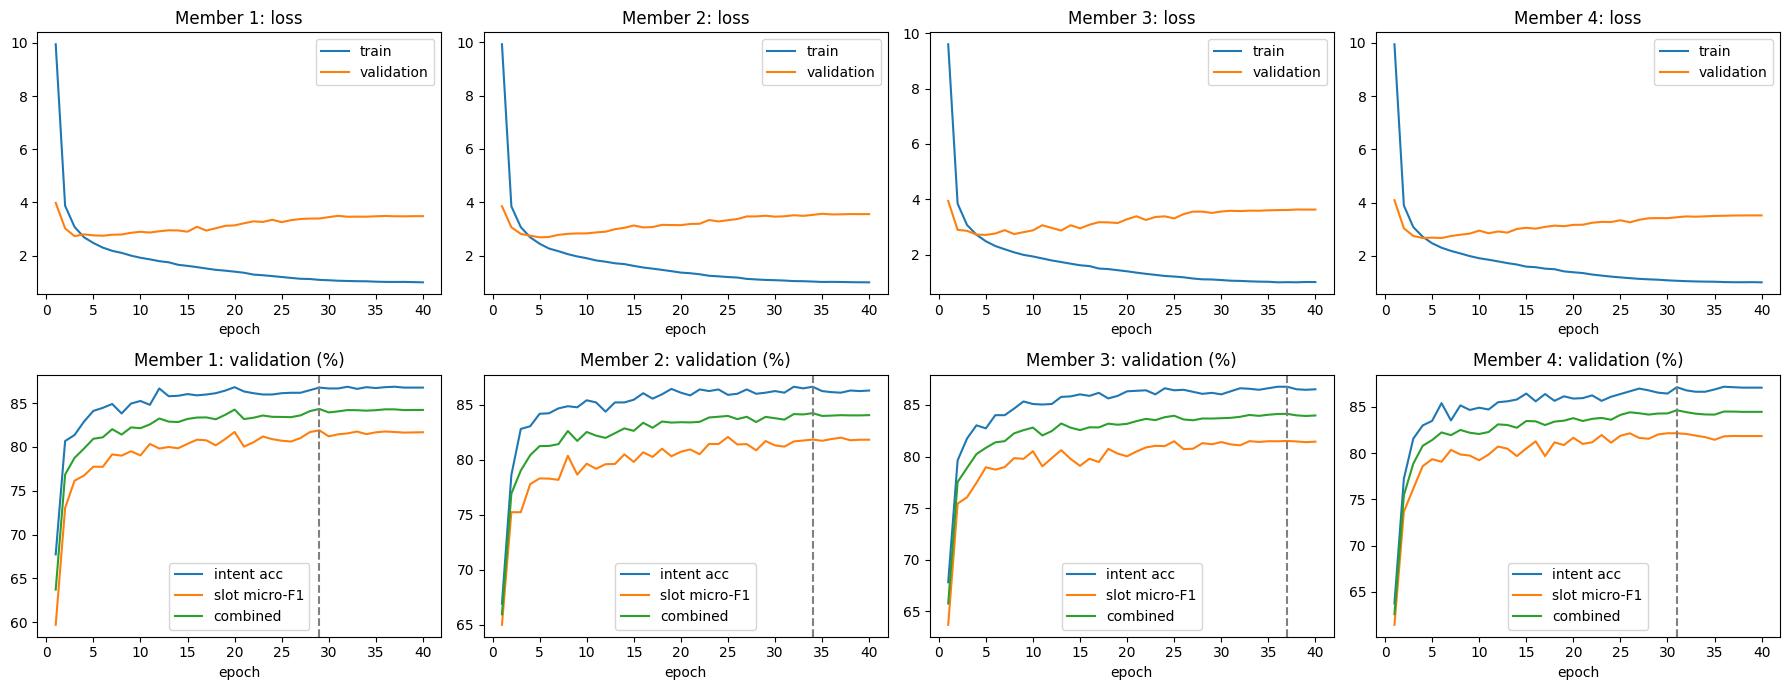

,member,best epoch,val intent (%),val slot F1 (%),val combined,train time (min),checkpoint
0,1,29,86.77,81.90,84.33,18.6,stage2_final_outputs/member1_seed42.pt
1,2,34,86.62,81.82,84.22,19.5,stage2_final_outputs/member2_seed43.pt
2,3,37,86.77,81.52,84.14,21.4,stage2_final_outputs/member3_seed44.pt
3,4,31,87.11,82.13,84.62,21.2,stage2_final_outputs/member4_seed45.pt


In [8]:
fig, axes = plt.subplots(2, N_MEMBERS, figsize=(4.5 * N_MEMBERS, 7), squeeze=False)
for i, run in enumerate(runs):
    h = run["history"]; ep = [r["epoch"] for r in h]
    ax = axes[0][i]
    ax.plot(ep, [r["train_loss"] for r in h], label="train"); ax.plot(ep, [r["validation_loss"] for r in h], label="validation")
    ax.set(title=f"Member {i+1}: loss", xlabel="epoch"); ax.legend()
    ax = axes[1][i]
    ax.plot(ep, [r["validation_intent_accuracy"] for r in h], label="intent acc")
    ax.plot(ep, [r["validation_slot_micro_f1"] for r in h], label="slot micro-F1")
    ax.plot(ep, [r["selection_score"] for r in h], label="combined")
    ax.axvline(run["best"]["epoch"], ls="--", c="grey"); ax.set(title=f"Member {i+1}: validation (%)", xlabel="epoch"); ax.legend()
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "learning_curves.png", dpi=150); plt.show()

rows = []
for i, run in enumerate(runs, 1):
    b = run["best"]
    rows.append({"member": i, "best epoch": b["epoch"], "val intent (%)": round(b["intent_accuracy"], 2),
                 "val slot F1 (%)": round(b["slot_micro_f1"], 2), "val combined": round(b["score"], 2),
                 "train time (min)": round(sum(r["epoch_seconds"] for r in run["history"]) / 60, 1),
                 "checkpoint": str(run["checkpoint"])})
pd.DataFrame(rows)

### Assemble the ensemble checkpoint and record its validation score

In [9]:
ENSEMBLE_CKPT = OUTPUT_DIR / "best_bigru_stage2_ensemble.pt"
s2.save_ensemble([r["checkpoint"] for r in runs], data, ENSEMBLE_CKPT)
loaders = s2.make_loaders(data, 32, 0)
ens, _ = s2.load_ensemble(ENSEMBLE_CKPT, data)
ensemble_val = s2.evaluate(ens, loaders["dev"], "cpu", data["id_to_tag"])
del ens
print(f"Member best epochs: {[r['best']['epoch'] for r in runs]}")
print(f"Ensemble validation score (combined): {ensemble_val['combined']:.2f} "
      f"(intent {ensemble_val['intent_accuracy']:.2f}%, slot micro-F1 {ensemble_val['slot_micro_f1']:.2f}%)")
print(f"Checkpoint filename: {ENSEMBLE_CKPT}")

Member best epochs: [29, 34, 37, 31]
Ensemble validation score (combined): 85.65 (intent 87.75%, slot micro-F1 83.54%)
Checkpoint filename: stage2_final_outputs/best_bigru_stage2_ensemble.pt


## 6. Final evaluation of the Stage-2 checkpoint (reloaded, no further training)

In [10]:
model, saved = s2.load_ensemble(ENSEMBLE_CKPT, data)
print("Loaded", ENSEMBLE_CKPT, "| members from", saved["member_files"])
preds, stage2_results = {}, {}
for split in ["dev", "test"]:
    preds[split] = s2.predict(model, loaders[split], "cpu", data["id_to_tag"])
    stage2_results[split] = s2.compute_metrics(preds[split]["pred_intents"], preds[split]["gold_intents"],
                                               preds[split]["pred_slots"], preds[split]["gold_slots"])
    r = stage2_results[split]
    print(f"Stage-2 {split:4s}: intent {r['intent_accuracy']:.2f}% | slot micro-F1 {r['slot_micro_f1']:.2f}%")
assert abs(stage2_results["dev"]["combined"] - ensemble_val["combined"]) < 1e-9
print("Reloaded validation score equals the validation score recorded after training.")

Loaded stage2_final_outputs/best_bigru_stage2_ensemble.pt | members from ['stage2_final_outputs/member1_seed42.pt', 'stage2_final_outputs/member2_seed43.pt', 'stage2_final_outputs/member3_seed44.pt', 'stage2_final_outputs/member4_seed45.pt']


Stage-2 dev : intent 87.75% | slot micro-F1 83.54%


Stage-2 test: intent 87.73% | slot micro-F1 81.55%
Reloaded validation score equals the validation score recorded after training.


## 7. Results table (all numbers computed in this notebook)

In [11]:
# Ablation rows: single members (no ensembling) and the earlier no-GloVe Stage-2 model.
single = {}
for i, run in enumerate(runs, 1):
    m, _ = s2.load_checkpoint(run["checkpoint"], data)
    single[i] = {s: s2.evaluate(m, loaders[s], "cpu", data["id_to_tag"]) for s in ["dev", "test"]}

data_noglove = s2.prepare(DATA_PATH)
m_ng, saved_ng = s2.load_checkpoint("stage2_enhanced_outputs/best_bigru_stage2.pt", data_noglove)
ld_ng = s2.make_loaders(data_noglove, 32, 0)
noglove = {s: s2.evaluate(m_ng, ld_ng[s], "cpu", data_noglove["id_to_tag"]) for s in ["dev", "test"]}
ng_total, ng_trainable = s2.count_parameters(m_ng)

def row(name, res, tot, trn, epochs):
    return [{"Model version": name, "Split": lab, "Total # parameters": f"{tot:,}", "Total # trainable parameters": f"{trn:,}",
             "Intent accuracy (%)": f"{res[s]['intent_accuracy']:.2f}", "Slot micro-F1 (%)": f"{res[s]['slot_micro_f1']:.2f}",
             "Number of epochs": epochs} for s, lab in [("dev", "Validation"), ("test", "Test")]]

main_table = pd.DataFrame(
    row("Stage-1 system", stage1_results, stage1_params, stage1_params, stage1_epoch)
    + row("Stage-2 system", stage2_results, total_params, trainable_params,
          f"{N_MEMBERS} members × best of {MEMBER_CONFIG['epochs']} (" + "/".join(str(r['best']['epoch']) for r in runs) + ")"))
main_table.to_csv(OUTPUT_DIR / "comparison_table.csv", index=False)
display(main_table)

ablation = pd.DataFrame(
    row("Stage-1 baseline", stage1_results, stage1_params, stage1_params, stage1_epoch)
    + row("+ Stage-2 changes, no GloVe (single model)", noglove, ng_total, ng_trainable, saved_ng["epoch"])
    + sum([row(f"+ GloVe, single member {i}", single[i], m_total, m_trainable, runs[i-1]['best']['epoch']) for i in single], [])
    + row(f"+ {N_MEMBERS}-member ensemble (final)", stage2_results, total_params, trainable_params, "-"))
ablation.to_csv(OUTPUT_DIR / "ablation_table.csv", index=False)
ablation

Dataset split sizes: {'train': 11514, 'dev': 2033, 'test': 2974}
Vocabulary size: 5146
Number of intents: 60
Number of BIO tags: 111


Character vocabulary size: 34


,Model version,Split,Total # parameters,Total # trainable parameters,Intent accuracy (%),Slot micro-F1 (%),Number of epochs
0,Stage-1 system,Validation,"1,044,435","1,044,435",84.01,78.98,30
1,Stage-1 system,Test,"1,044,435","1,044,435",82.82,75.63,30
2,Stage-2 system,Validation,"19,758,612","12,214,812",87.75,83.54,4 members × best of 40 (29/34/37/31)
3,Stage-2 system,Test,"19,758,612","12,214,812",87.73,81.55,4 members × best of 40 (29/34/37/31)


,Model version,Split,Total # parameters,Total # trainable parameters,Intent accuracy (%),Slot micro-F1 (%),Number of epochs
0,Stage-1 baseline,Validation,"1,044,435","1,044,435",84.01,78.98,30
1,Stage-1 baseline,Test,"1,044,435","1,044,435",82.82,75.63,30
2,"+ Stage-2 changes, no GloVe (single model)",Validation,"4,931,523","4,931,523",85.24,80.21,35
3,"+ Stage-2 changes, no GloVe (single model)",Test,"4,931,523","4,931,523",84.63,78.37,35
4,"+ GloVe, single member 1",Validation,"10,597,503","3,053,703",86.77,81.90,29
5,"+ GloVe, single member 1",Test,"10,597,503","3,053,703",86.01,79.50,29
6,"+ GloVe, single member 2",Validation,"10,597,503","3,053,703",86.62,81.82,34
7,"+ GloVe, single member 2",Test,"10,597,503","3,053,703",86.01,79.71,34
8,"+ GloVe, single member 3",Validation,"10,597,503","3,053,703",86.77,81.52,37
9,"+ GloVe, single member 3",Test,"10,597,503","3,053,703",86.21,79.89,37


## 8. Error analysis on the test set (final Stage-2 system)

In [12]:
id_to_intent = {i: n for n, i in data["intent_to_id"].items()}
p = preds["test"]
intent_errors = Counter((id_to_intent[g], id_to_intent[q]) for g, q in zip(p["gold_intents"], p["pred_intents"]) if g != q)
print("Most frequent intent confusions (gold -> predicted):")
for (g, q), c in intent_errors.most_common(10):
    print(f"  {c:3d}  {g} -> {q}")

per_type, fn_type, fp_type = Counter(), Counter(), Counter()
for ps, gs in zip(p["pred_slots"], p["gold_slots"]):
    for t, _ in gs: per_type[t] += 1
    for t, _ in gs - ps: fn_type[t] += 1
    for t, _ in ps - gs: fp_type[t] += 1
print("\nSlot types with the most errors:")
for t, _ in (fn_type + fp_type).most_common(10):
    print(f"  {t:20s} gold={per_type[t]:4d}  FN={fn_type[t]:3d}  FP={fp_type[t]:3d}")

Most frequent intent confusions (gold -> predicted):
   15  general_quirky -> qa_factoid
   11  qa_factoid -> general_quirky
   10  general_quirky -> calendar_query
    9  general_quirky -> news_query
    8  calendar_set -> calendar_query
    5  play_music -> play_audiobook
    5  general_quirky -> weather_query
    4  news_query -> general_quirky
    4  iot_hue_lightchange -> iot_hue_lightup
    4  calendar_query -> calendar_set

Slot types with the most errors:
  event_name           gold= 260  FN= 53  FP= 47
  date                 gold= 416  FN= 32  FP= 53
  place_name           gold= 281  FN= 38  FP= 44
  time                 gold= 193  FN= 38  FP= 35
  person               gold= 219  FN= 22  FP= 34
  business_name        gold=  92  FN= 25  FP= 20
  food_type            gold=  72  FN= 16  FP= 28
  news_topic           gold=  49  FN= 21  FP= 16
  media_type           gold= 128  FN= 20  FP= 16
  weather_descriptor   gold=  82  FN= 13  FP= 17


In [13]:
oov_flags = [any(w.lower() not in train_counts for w in stage1.record_to_tokens_tags(r)[0]) for r in splits["test"]]
for flag, name in [(True, "with unseen word"), (False, "no unseen word")]:
    idx = [i for i, f in enumerate(oov_flags) if f == flag]
    for label, pr in [("Stage-2 final", p)]:
        m = s2.compute_metrics([pr["pred_intents"][i] for i in idx], [pr["gold_intents"][i] for i in idx],
                               [pr["pred_slots"][i] for i in idx], [pr["gold_slots"][i] for i in idx])
        print(f"{label}: test utterances {name:16s} (n={len(idx):4d}): intent {m['intent_accuracy']:.2f}% | slot F1 {m['slot_micro_f1']:.2f}%")

print("\nExample errors:")
shown = 0
for i, (utt, gi, pi, gs, ps) in enumerate(zip(p["utts"], p["gold_intents"], p["pred_intents"], p["gold_slots"], p["pred_slots"])):
    if (gi != pi or gs != ps) and i % 7 == 0:
        print(f"- utt: {utt}")
        print(f"  intent gold={id_to_intent[gi]}  pred={id_to_intent[pi]}")
        print(f"  slots  gold={sorted(gs)}")
        print(f"         pred={sorted(ps)}")
        shown += 1
    if shown == 10:
        break

Stage-2 final: test utterances with unseen word (n= 541): intent 78.56% | slot F1 70.74%
Stage-2 final: test utterances no unseen word   (n=2433): intent 89.77% | slot F1 84.40%

Example errors:
- utt: i want the status on my screen brightness
  intent gold=general_quirky  pred=iot_hue_lightup
  slots  gold=[]
         pred=[('device_type', 'screen')]
- utt: i like senatra songs
  intent gold=music_likeness  pred=music_likeness
  slots  gold=[('artist_name', 'senatra')]
         pred=[('music_genre', 'senatra')]
- utt: seven years
  intent gold=play_music  pred=calendar_set
  slots  gold=[('song_name', 'seven years')]
         pred=[]
- utt: by get marks
  intent gold=weather_query  pred=audio_volume_mute
  slots  gold=[]
         pred=[]
- utt: i want to hear snow by red hot chili peppers
  intent gold=play_music  pred=play_music
  slots  gold=[('artist_name', 'red hot chili peppers'), ('song_name', 'snow')]
         pred=[('artist_name', 'red hot chili'), ('song_name', 'snow')]
- utt